In [765]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE
from category_encoders import HashingEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingClassifier


In [766]:
# from google.colab import drive
# drive.mount('/content/drive')

In [767]:
df_train = pd.read_csv("data/train_Insurance.csv")
df_test = pd.read_csv("data/test_Insurance.csv")
df_train

,Customer Id,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,NumberOfWindows,Geo_Code,Claim
0,H13501,2012,1.0,1,N,V,V,U,1240.0,Wood-framed,without,75117,non
1,H14962,2012,1.0,0,N,V,V,U,900.0,Non-combustible,without,62916,non
2,H17755,2013,1.0,1,V,N,O,R,4984.0,Non-combustible,4,31149,oui
3,H13369,2016,0.5,0,N,V,V,U,600.0,Wood-framed,without,6012,oui
4,H12988,2012,1.0,0,N,V,V,U,900.0,Non-combustible,without,57631,non
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,H13682,2013,1.0,0,N,V,V,U,550.0,Ordinary,without,33063,oui
5008,H18342,2012,0.5,0,V,N,O,R,1000.0,Fire-resistive,4,13004,non
5009,H16892,2015,1.0,1,V,N,O,R,480.0,Ordinary,3,94059,non
5010,H18805,2012,0.5,0,V,N,O,R,536.0,Fire-resistive,4,74243,non


In [768]:
df_train.describe(include="all")


,Customer Id,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,NumberOfWindows,Geo_Code,Claim
count,5012,5012.000000,5012.000000,5012.000000,5012,5012,5008,5012,4935.000000,5012,5012,4939,5012
unique,5012,NaN,NaN,NaN,2,2,2,2,NaN,4,11,1115,2
top,H13501,NaN,NaN,NaN,V,N,O,R,NaN,Non-combustible,without,6088,non
freq,1,NaN,NaN,NaN,3763,2535,2532,2537,NaN,2310,2476,102,3886
mean,NaN,2013.660215,0.869713,0.301077,NaN,NaN,NaN,NaN,1876.898683,NaN,NaN,NaN,NaN
std,NaN,1.383134,0.219496,0.458772,NaN,NaN,NaN,NaN,2267.277397,NaN,NaN,NaN,NaN
min,NaN,2012.000000,0.500000,0.000000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2012.000000,0.500000,0.000000,NaN,NaN,NaN,NaN,520.000000,NaN,NaN,NaN,NaN
50%,NaN,2013.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,1067.000000,NaN,NaN,NaN,NaN
75%,NaN,2015.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,2280.000000,NaN,NaN,NaN,NaN


In [769]:
df_train.isna().sum()

Customer Id            0
YearOfObservation      0
Insured_Period         0
Residential            0
Building_Painted       0
Building_Fenced        0
Garden                 4
Settlement             0
Building Dimension    77
Building_Type          0
NumberOfWindows        0
Geo_Code              73
Claim                  0
dtype: int64

In [770]:
print(f"claim=oui {len(df_train[df_train["Claim"]=="oui"])/len(df_train)*100:.2f}%")
print(f"claim=non {len(df_train[df_train["Claim"]=="non"])/len(df_train)*100:.2f}%")

claim=oui 22.47%
claim=non 77.53%


<Axes: xlabel='Claim', ylabel='Count'>

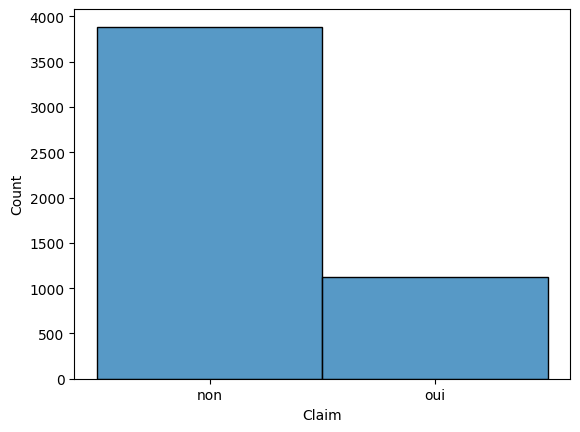

In [771]:
sns.histplot(df_train, x="Claim")

 removing Customer Id because it doesn't effect the data

In [772]:
df_train.drop(columns=["Customer Id"], inplace=True)
df_test.drop(columns=["Customer Id"], inplace=True)


In [773]:
df_train["NumberOfWindows"].value_counts()

NumberOfWindows
without    2476
4           667
3           600
5           436
2           245
6           225
7           142
8            84
>=10         53
1            49
9            35
Name: count, dtype: int64

replace the without with 0 and >=10 with 10

In [774]:
df_train["NumberOfWindows"] = (
    df_train["NumberOfWindows"].replace("without", 0).replace(">=10", 10).astype(int)
)
df_test["NumberOfWindows"] = (
    df_test["NumberOfWindows"].replace("without", 0).replace(">=10", 10).astype(int)
)
df_train["NumberOfWindows"].value_counts()

NumberOfWindows
0     2476
4      667
3      600
5      436
2      245
6      225
7      142
8       84
10      53
1       49
9       35
Name: count, dtype: int64

# encoding

In [775]:
for i in df_train.columns:
    print(i)
    print(df_train[i].unique())

YearOfObservation
[2012 2013 2016 2014 2015]
Insured_Period
[1.  0.5]
Residential
[1 0]
Building_Painted
['N' 'V']
Building_Fenced
['V' 'N']
Garden
['V' 'O' nan]
Settlement
['U' 'R']
Building Dimension
[ 1240.   900.  4984. ...  4430. 16459.   173.]
Building_Type
['Wood-framed' 'Non-combustible' 'Ordinary' 'Fire-resistive']
NumberOfWindows
[ 0  4  2  7  5  3  8 10  6  1  9]
Geo_Code
['75117' '62916' '31149' ... '45232' '42225' '94059']
Claim
['non' 'oui']


create a new label for missing values in geo code as it a categorical feature

In [776]:
df_train["Geo_Code"] = df_train["Geo_Code"].fillna(-1)
df_test["Geo_Code"] = df_test["Geo_Code"].fillna(-1)

can't use an ordinal encoder as zip code is a high cardinality categorical feature and new values can appear in the test set

In [777]:
# encoder=OrdinalEncoder()
# encoder=encoder.fit(df_train[["Geo_Code"]])
# df_train["Geo_Code"]=encoder.transform(df_train[["Geo_Code"]])
# df_test["Geo_Code"]=encoder.transform(df_test[["Geo_Code"]])

In [778]:
encoder = HashingEncoder(n_components=8)

encoder.fit(df_train[["Geo_Code"]])

geo_train = encoder.transform(df_train[["Geo_Code"]])
geo_test = encoder.transform(df_test[["Geo_Code"]])

df_train = df_train.drop(columns=["Geo_Code"]).join(geo_train)
df_test = df_test.drop(columns=["Geo_Code"]).join(geo_test)

###

In [779]:
ord_categories = [[0.5, 1], ["V", "N"], ["V", "N"], ["R", "U"], ["oui", "non"]]
enc = OrdinalEncoder(categories=ord_categories)
enc =enc.fit(
    df_train[
        ["Insured_Period", "Building_Painted", "Building_Fenced", "Settlement", "Claim"]
    ]
)
df_train[
    ["Insured_Period", "Building_Painted", "Building_Fenced", "Settlement", "Claim"]
] = enc.transform(
    df_train[
        ["Insured_Period", "Building_Painted", "Building_Fenced", "Settlement", "Claim"]
    ]
)
df_test[
    ["Insured_Period", "Building_Painted", "Building_Fenced", "Settlement", "Claim"]
] = enc.transform(
    df_test[
        ["Insured_Period", "Building_Painted", "Building_Fenced", "Settlement", "Claim"]
    ]
)

df_train

,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,Building_Type,NumberOfWindows,Claim,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7
0,2012,1.0,1,1.0,0.0,V,1.0,1240.0,Wood-framed,0,1.0,0,0,0,1,0,0,0,0
1,2012,1.0,0,1.0,0.0,V,1.0,900.0,Non-combustible,0,1.0,0,0,0,0,0,0,0,1
2,2013,1.0,1,0.0,1.0,O,0.0,4984.0,Non-combustible,4,0.0,0,0,0,0,1,0,0,0
3,2016,0.0,0,1.0,0.0,V,1.0,600.0,Wood-framed,0,0.0,0,0,0,0,1,0,0,0
4,2012,1.0,0,1.0,0.0,V,1.0,900.0,Non-combustible,0,1.0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013,1.0,0,1.0,0.0,V,1.0,550.0,Ordinary,0,0.0,0,0,1,0,0,0,0,0
5008,2012,0.0,0,0.0,1.0,O,0.0,1000.0,Fire-resistive,4,1.0,0,0,0,1,0,0,0,0
5009,2015,1.0,1,0.0,1.0,O,0.0,480.0,Ordinary,3,1.0,0,0,1,0,0,0,0,0
5010,2012,0.0,0,0.0,1.0,O,0.0,536.0,Fire-resistive,4,1.0,0,0,0,0,0,0,0,1


In [780]:
enc = OneHotEncoder(
    sparse_output=False,
    categories=[["Wood-framed", "Non-combustible", "Ordinary", "Fire-resistive"]],
)
encoded_train=enc.fit(df_train[["Building_Type"]]).transform(df_train[["Building_Type"]])
encoded_test=enc.fit(df_train[["Building_Type"]]).transform(df_test[["Building_Type"]])
df_train = pd.concat(
    [
        df_train,
        pd.DataFrame(
            encoded_train, columns=["Wood-framed", "Non-combustible", "Ordinary", "Fire-resistive"]
        ),
    ],
    axis=1,
)
df_test = pd.concat(
    [
        df_test,
        pd.DataFrame(
            encoded_test, columns=["Wood-framed", "Non-combustible", "Ordinary", "Fire-resistive"]
        ),
    ],
    axis=1,
)
df_train.drop(columns=["Building_Type"], inplace=True)
df_test.drop(columns=["Building_Type"], inplace=True)
# df_train = pd.concat(
#     [
#         df_train.iloc[:, :-6],
#         df_train.iloc[:, -4:],
#         df_train.iloc[:, [-6]],
#         df_train.iloc[:, [-5]],
#     ],
#     axis=1,
# )
# df_test = pd.concat(
#     [
#         df_test.iloc[:, :-6],
#         df_test.iloc[:, -4:],
#         df_test.iloc[:, [-6]],
#         df_test.iloc[:, [-5]],
#     ],
#     axis=1,
# )
df_test

,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,NumberOfWindows,Claim,...,col_2,col_3,col_4,col_5,col_6,col_7,Wood-framed,Non-combustible,Ordinary,Fire-resistive
0,2013,1.0,0,0.0,0.0,V,1.0,3760.0,0,0.0,...,0,0,1,0,0,0,0.0,0.0,0.0,1.0
1,2015,1.0,0,0.0,1.0,O,0.0,1452.0,5,1.0,...,0,0,0,0,0,0,0.0,0.0,0.0,1.0
2,2013,1.0,1,0.0,1.0,O,0.0,1944.0,6,0.0,...,0,0,0,1,0,0,0.0,0.0,1.0,0.0
3,2015,1.0,0,1.0,0.0,V,1.0,2270.0,0,0.0,...,0,0,0,0,0,0,0.0,1.0,0.0,0.0
4,2016,0.0,0,0.0,1.0,O,0.0,2976.0,9,1.0,...,0,0,0,0,0,1,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.0,1,0.0,1.0,O,0.0,862.0,2,1.0,...,0,0,0,0,0,1,1.0,0.0,0.0,0.0
2143,2012,1.0,0,0.0,0.0,V,1.0,NaN,0,1.0,...,0,0,0,0,0,0,0.0,1.0,0.0,0.0
2144,2014,1.0,0,0.0,1.0,O,0.0,730.0,3,1.0,...,1,0,0,0,0,0,0.0,1.0,0.0,0.0
2145,2014,1.0,1,1.0,0.0,V,1.0,568.0,0,0.0,...,1,0,0,0,0,0,0.0,1.0,0.0,0.0


# Filling  Nan

In [781]:
df_train.isna().sum()

YearOfObservation      0
Insured_Period         0
Residential            0
Building_Painted       0
Building_Fenced        0
Garden                 4
Settlement             0
Building Dimension    77
NumberOfWindows        0
Claim                  0
col_0                  0
col_1                  0
col_2                  0
col_3                  0
col_4                  0
col_5                  0
col_6                  0
col_7                  0
Wood-framed            0
Non-combustible        0
Ordinary               0
Fire-resistive         0
dtype: int64

In [782]:
df_test.isna().sum()

YearOfObservation      0
Insured_Period         0
Residential            0
Building_Painted       0
Building_Fenced        0
Garden                 3
Settlement             0
Building Dimension    29
NumberOfWindows        0
Claim                  0
col_0                  0
col_1                  0
col_2                  0
col_3                  0
col_4                  0
col_5                  0
col_6                  0
col_7                  0
Wood-framed            0
Non-combustible        0
Ordinary               0
Fire-resistive         0
dtype: int64

In [783]:
#df_train["Geo_Code"]=df_train.sort_values(by="Ordinary",ascending=True)["Geo_Code"].ffill().sort_index()
#df_train

In [784]:
df_train.corr(numeric_only=True)["Building Dimension"]

YearOfObservation     0.005221
Insured_Period       -0.010447
Residential           0.066821
Building_Painted     -0.096541
Building_Fenced       0.141988
Settlement           -0.141922
Building Dimension    1.000000
NumberOfWindows       0.301206
Claim                -0.288224
col_0                -0.021717
col_1                 0.049491
col_2                -0.040557
col_3                 0.015055
col_4                -0.014258
col_5                 0.011980
col_6                 0.015802
col_7                -0.013012
Wood-framed           0.020280
Non-combustible      -0.007556
Ordinary             -0.013044
Fire-resistive        0.004371
Name: Building Dimension, dtype: float64

In [785]:
mf_imputer = SimpleImputer(missing_values=np.nan,strategy='most_frequent')
df_train['Building Dimension']=mf_imputer.fit_transform(df_train.loc[:,['Building Dimension']])
df_test["Building Dimension"]=mf_imputer.fit_transform(df_test.loc[:,["Building Dimension"]])

In [786]:
df_train[["Garden"]]=SimpleImputer(missing_values=np.nan,strategy="most_frequent").fit_transform(df_train.loc[:,["Garden"]])
df_test[["Garden"]]=SimpleImputer(missing_values=np.nan,strategy="most_frequent").fit_transform(df_test.loc[:,["Garden"]])

In [787]:
df_train.corr(method="spearman",numeric_only=True)

,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Settlement,Building Dimension,NumberOfWindows,Claim,col_0,...,col_2,col_3,col_4,col_5,col_6,col_7,Wood-framed,Non-combustible,Ordinary,Fire-resistive
YearOfObservation,1.000000,-0.277814,-0.026377,-0.050347,0.123231,-0.122916,0.044586,0.116543,0.016458,-0.037333,...,-0.026972,0.018805,0.031611,0.010211,-0.000047,0.007773,0.004807,-0.015552,0.003818,0.011020
Insured_Period,-0.277814,1.000000,-0.039430,0.036210,-0.015859,0.016294,0.012465,-0.015998,-0.070145,-0.002175,...,-0.008306,0.002939,0.024537,0.020453,-0.004823,0.005353,0.011621,-0.001890,-0.010239,0.002119
Residential,-0.026377,-0.039430,1.000000,0.017048,0.090274,-0.090621,0.073360,0.126279,-0.055220,0.024173,...,0.002403,-0.002916,0.000012,-0.035394,0.016458,-0.001809,0.241144,-0.192391,0.221975,-0.159589
Building_Painted,-0.050347,0.036210,0.017048,1.000000,-0.578215,0.578680,-0.101871,-0.534786,0.036031,-0.020474,...,0.018692,0.028426,-0.012069,-0.026219,0.021682,-0.020535,0.030018,0.003094,0.016172,-0.041328
Building_Fenced,0.123231,-0.015859,0.090274,-0.578215,1.000000,-0.999202,0.165516,0.925300,-0.069308,-0.033129,...,-0.005613,-0.034167,0.023649,0.037321,-0.012264,0.035970,0.015250,-0.007498,0.012799,-0.014449
Settlement,-0.122916,0.016294,-0.090621,0.578680,-0.999202,1.000000,-0.165213,-0.925666,0.069836,0.033414,...,0.004877,0.034446,-0.024538,-0.037040,0.012557,-0.035668,-0.014944,0.006635,-0.012438,0.014898
Building Dimension,0.044586,0.012465,0.073360,-0.101871,0.165516,-0.165213,1.000000,0.284022,-0.274699,-0.080034,...,-0.060774,0.001864,0.021401,0.025022,0.016347,0.023164,0.044431,-0.040197,-0.033913,0.041956
NumberOfWindows,0.116543,-0.015998,0.126279,-0.534786,0.925300,-0.925666,0.284022,1.000000,-0.133885,-0.024561,...,-0.013689,-0.023342,0.024803,0.018196,-0.004768,0.035951,0.082465,-0.049442,0.039236,-0.041382
Claim,0.016458,-0.070145,-0.055220,0.036031,-0.069308,0.069836,-0.274699,-0.133885,1.000000,-0.008824,...,0.022503,-0.005467,-0.025755,0.003414,0.019367,0.007665,-0.110850,0.038330,-0.020522,0.060091
col_0,-0.037333,-0.002175,0.024173,-0.020474,-0.033129,0.033414,-0.080034,-0.024561,-0.008824,1.000000,...,-0.156307,-0.124627,-0.136635,-0.125651,-0.131203,-0.135165,0.008269,0.003964,-0.029243,0.014634


In [788]:
df_test.isna().sum()

YearOfObservation     0
Insured_Period        0
Residential           0
Building_Painted      0
Building_Fenced       0
Garden                0
Settlement            0
Building Dimension    0
NumberOfWindows       0
Claim                 0
col_0                 0
col_1                 0
col_2                 0
col_3                 0
col_4                 0
col_5                 0
col_6                 0
col_7                 0
Wood-framed           0
Non-combustible       0
Ordinary              0
Fire-resistive        0
dtype: int64

# Outliers

looking at the table df.describe we can conclude that there is 4 columns that can have outliers since they are numbers and not objects.however,yearsofobservation has min of 2013 and max of 2016 we don't need to check for outliers for that columns,insured Period  and residential has 2 values {0,1} so there is only one columns that has possible outliers which is building dimension

<Axes: xlabel='Building Dimension'>

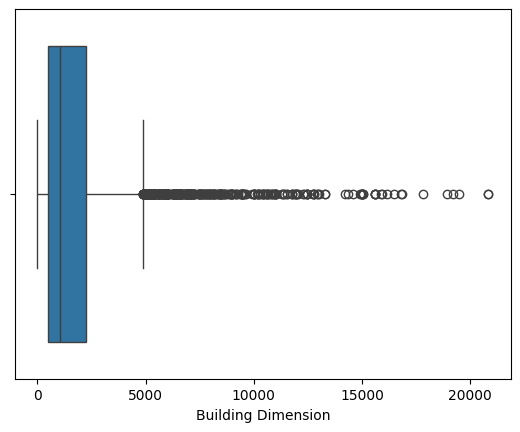

In [789]:
sns.boxplot(df_train,x="Building Dimension")

Too many outliers so we can't really remove them so we are going to try standardization the column using RobustScaler

# Standadization

(np.float64(1854.2088986432561), np.float64(1037.5))

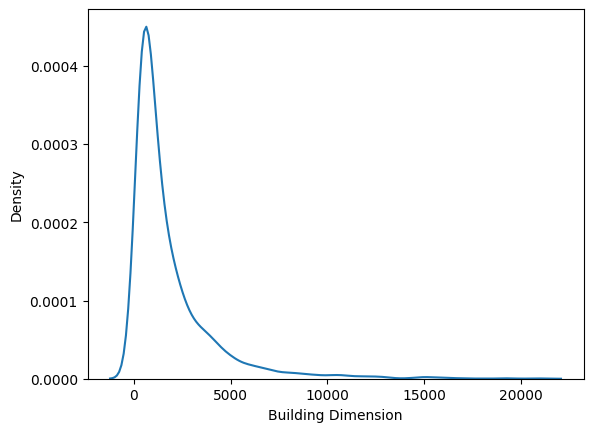

In [790]:
sns.kdeplot(df_train, x="Building Dimension", bw_method="scott", bw_adjust=1)
df_train["Building Dimension"].mean(), df_train["Building Dimension"].median()

its Asymtric so using RobustScaler is good

In [791]:
df_train['Building Dimension']=RobustScaler().fit_transform(df_train[["Building Dimension"]])
df_test["Building Dimension"]=RobustScaler().fit_transform(df_test[["Building Dimension"]])

### fixing Garden 

In [792]:
df_train["Garden"]=df_train["Garden"].map(lambda x: 1 if x=="V" else 0)
df_test["Garden"]=df_test["Garden"].map(lambda x: 1 if x=="V" else 0)

# Checkpoint

In [793]:
df_train

,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,NumberOfWindows,Claim,...,col_2,col_3,col_4,col_5,col_6,col_7,Wood-framed,Non-combustible,Ordinary,Fire-resistive
0,2012,1.0,1,1.0,0.0,1,1.0,0.115714,0,1.0,...,0,1,0,0,0,0,1.0,0.0,0.0,0.0
1,2012,1.0,0,1.0,0.0,1,1.0,-0.078571,0,1.0,...,0,0,0,0,0,1,0.0,1.0,0.0,0.0
2,2013,1.0,1,0.0,1.0,0,0.0,2.255143,4,0.0,...,0,0,1,0,0,0,0.0,1.0,0.0,0.0
3,2016,0.0,0,1.0,0.0,1,1.0,-0.250000,0,0.0,...,0,0,1,0,0,0,1.0,0.0,0.0,0.0
4,2012,1.0,0,1.0,0.0,1,1.0,-0.078571,0,1.0,...,1,0,0,0,0,0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013,1.0,0,1.0,0.0,1,1.0,-0.278571,0,0.0,...,1,0,0,0,0,0,0.0,0.0,1.0,0.0
5008,2012,0.0,0,0.0,1.0,0,0.0,-0.021429,4,1.0,...,0,1,0,0,0,0,0.0,0.0,0.0,1.0
5009,2015,1.0,1,0.0,1.0,0,0.0,-0.318571,3,1.0,...,1,0,0,0,0,0,0.0,0.0,1.0,0.0
5010,2012,0.0,0,0.0,1.0,0,0.0,-0.286571,4,1.0,...,0,0,0,0,0,1,0.0,0.0,0.0,1.0


In [794]:
df_train.describe(include="all")

,YearOfObservation,Insured_Period,Residential,Building_Painted,Building_Fenced,Garden,Settlement,Building Dimension,NumberOfWindows,Claim,...,col_2,col_3,col_4,col_5,col_6,col_7,Wood-framed,Non-combustible,Ordinary,Fire-resistive
count,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,...,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000,5012.000000
mean,2013.660215,0.739425,0.301077,0.249202,0.505786,0.494014,0.493815,0.466691,2.204310,0.775339,...,0.161014,0.108739,0.127893,0.110335,0.119114,0.125499,0.128292,0.460894,0.170391,0.240423
std,1.383134,0.438992,0.458772,0.432594,0.500016,0.500014,0.500012,1.289779,2.535589,0.417400,...,0.367580,0.311343,0.334004,0.313338,0.323955,0.331317,0.334448,0.498518,0.376014,0.427383
min,2012.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.592286,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2012.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.307143,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2013.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2015.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.692857,4.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,2016.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,11.315714,10.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [795]:
df_train.isna().sum()

YearOfObservation     0
Insured_Period        0
Residential           0
Building_Painted      0
Building_Fenced       0
Garden                0
Settlement            0
Building Dimension    0
NumberOfWindows       0
Claim                 0
col_0                 0
col_1                 0
col_2                 0
col_3                 0
col_4                 0
col_5                 0
col_6                 0
col_7                 0
Wood-framed           0
Non-combustible       0
Ordinary              0
Fire-resistive        0
dtype: int64

it appears to have 77.5% of that data with the class yes 

In [796]:
X = df_train.drop("Claim", axis=1)
y = df_train["Claim"]
X_test,Y_test= df_test.drop("Claim", axis=1),df_test["Claim"]



In [797]:
# Split train/test (stratify keeps Yes/No ratio same in both sets)
X_train, X_validation, y_train, y_validation = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
len(X)


5012

In [798]:
# Logistic Regression with class_weight="balanced"
clf = LogisticRegression(random_state=42, max_iter=6000)
clf.fit(X_train, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,6000
,multi_class,'deprecated'


In [799]:
y_pred = clf.predict(X_validation)
print(classification_report(y_validation, y_pred))

              precision    recall  f1-score   support

         0.0       0.67      0.12      0.20       225
         1.0       0.79      0.98      0.88       778

    accuracy                           0.79      1003
   macro avg       0.73      0.55      0.54      1003
weighted avg       0.77      0.79      0.73      1003



In [800]:
y_pred = clf.predict(X_test)
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.66      0.13      0.22       508
         1.0       0.78      0.98      0.87      1639

    accuracy                           0.78      2147
   macro avg       0.72      0.55      0.54      2147
weighted avg       0.75      0.78      0.72      2147



the model is working well with 1.0(yes) but strugles with 0.0(no) meaning we should do SMOTE oversampling 

# balancing the dataset

In [801]:
smote = SMOTE(random_state=42)
X_res, y_res= smote.fit_resample(X, y)
len(X)


5012

In [802]:
# Split train/test (stratify keeps Yes/No ratio same in both sets)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_res, y_res, test_size=0.2, stratify=y_res, random_state=42
)

In [803]:
# Logistic Regression with class_weight="balanced"
clf = LogisticRegression(random_state=42, max_iter=5000)
clf.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,5000
,multi_class,'deprecated'


In [804]:
y_pred = clf.predict(X_validation)
print(classification_report(y_validation, y_pred))

              precision    recall  f1-score   support

         0.0       0.73      0.54      0.62       778
         1.0       0.63      0.80      0.71       777

    accuracy                           0.67      1555
   macro avg       0.68      0.67      0.66      1555
weighted avg       0.68      0.67      0.66      1555



In [805]:
y_pred = clf.predict(X_test)
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.43      0.45      0.44       508
         1.0       0.83      0.82      0.82      1639

    accuracy                           0.73      2147
   macro avg       0.63      0.63      0.63      2147
weighted avg       0.73      0.73      0.73      2147



## training de model gradient boosting

In [806]:
gb = GradientBoostingClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42
)
gb.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.05
,n_estimators,200
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


### test de model sur donne de validation 

In [807]:
y_pred = gb.predict(X_validation)
print(classification_report(y_validation, y_pred))

              precision    recall  f1-score   support

         0.0       0.74      0.70      0.72       778
         1.0       0.71      0.76      0.74       777

    accuracy                           0.73      1555
   macro avg       0.73      0.73      0.73      1555
weighted avg       0.73      0.73      0.73      1555



## test de model sur donnee de test

In [808]:
y_pred = gb.predict(X_test)
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.41      0.52      0.46       508
         1.0       0.84      0.77      0.80      1639

    accuracy                           0.71      2147
   macro avg       0.63      0.65      0.63      2147
weighted avg       0.74      0.71      0.72      2147



NVM makes it worse XD

## training neural network model

In [809]:
clf = MLPClassifier(
    solver="lbfgs", alpha=1e-5, hidden_layer_sizes=( 20,10), random_state=1
    ,max_iter=100000
)
clf.fit(X_train, y_train)

,hidden_layer_sizes,"(20, ...)"
,activation,'relu'
,solver,'lbfgs'
,alpha,1e-05
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,100000
,shuffle,True
,random_state,1


In [810]:
y_pred = clf.predict(X_validation)
print(classification_report(y_validation, y_pred))

              precision    recall  f1-score   support

         0.0       0.66      0.62      0.64       778
         1.0       0.64      0.67      0.66       777

    accuracy                           0.65      1555
   macro avg       0.65      0.65      0.65      1555
weighted avg       0.65      0.65      0.65      1555



In [ ]:
print("hello")